In [ ]:
!pip install -q tensorflow matplotlib scikit-learn pillow

In [ ]:
import tensorflow as tf

print("TensorFlow:", tf.__version__)

gpu = tf.config.list_physical_devices('GPU')

if gpu:
    print("GPU Available:", gpu)
else:
    print("Running on CPU")

TensorFlow: 2.21.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
import tensorflow as tf
import platform

print("Python:", platform.python_version())
print("TensorFlow:", tf.__version__)
print("CPU:", platform.processor())
print("GPU:", tf.config.list_physical_devices('GPU'))

Python: 3.13.16
TensorFlow: 2.21.0
CPU: x86_64
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
!nvidia-smi

Wed Nov 25 15:13:27 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   53C    P8             13W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

dataset_path = "/content/drive/MyDrive/dataset"

print("Dataset exists:", os.path.exists(dataset_path))

if os.path.exists(dataset_path):
    print("\nDataset folders:")
    print(os.listdir(dataset_path))

Dataset exists: True

Dataset folders:
['Train', 'Test']


In [ ]:

import os

dataset_path = "/content/drive/MyDrive/dataset"

classes = [
    "freshapples",
    "rottenapples",
    "freshbanana",
    "rottenbanana",
    "freshoranges",
    "rottenoranges",
    "freshtomato",
    "rottentomato"
]

extensions = (".jpg", ".jpeg", ".png", ".webp")

for split in ["Train", "Test"]:

    print(f"\n===== {split.upper()} DATASET =====")

    total = 0

    for class_name in classes:

        folder = os.path.join(
            dataset_path, split, class_name
        )

        if not os.path.exists(folder):
            print(f"{class_name}: MISSING")
            continue

        images = [
            f for f in os.listdir(folder)
            if f.lower().endswith(extensions)
        ]

        count = len(images)
        total += count

        print(f"{class_name}: {count}")

    print("TOTAL IMAGES:", total)



===== TRAIN DATASET =====
freshapples: 2424
rottenapples: 3248
freshbanana: 2468
rottenbanana: 2932
freshoranges: 1466
rottenoranges: 1595
freshtomato: 1858
rottentomato: 1825
TOTAL IMAGES: 17816

===== TEST DATASET =====
freshapples: 791
rottenapples: 988
freshbanana: 892
rottenbanana: 900
freshoranges: 388
rottenoranges: 403
freshtomato: 255
rottentomato: 353
TOTAL IMAGES: 4970


In [ ]:
import os

test_path = "/content/drive/MyDrive/dataset/Test"

for folder in sorted(os.listdir(test_path)):
    path = os.path.join(test_path, folder)

    if os.path.isdir(path):
        print(folder, ":", len(os.listdir(path)))

freshapples : 791
freshbanana : 892
freshoranges : 388
freshtomato : 255
rottenapples : 988
rottenbanana : 900
rottenoranges : 403
rottentomato : 353


In [ ]:
import os

dataset_path = "/content/drive/MyDrive/dataset"

classes = [
    "freshapples",
    "rottenapples",
    "freshbanana",
    "rottenbanana",
    "freshoranges",
    "rottenoranges",
    "freshtomato",
    "rottentomato"
]

for split in ["Train", "Test"]:

    print(f"\n===== {split.upper()} =====")

    for class_name in classes:

        folder = os.path.join(
            dataset_path, split, class_name
        )

        if os.path.exists(folder):
            print(class_name, ":", len(os.listdir(folder)))
        else:
            print(class_name, ": MISSING")


===== TRAIN =====
freshapples : 2424
rottenapples : 3248
freshbanana : 2468
rottenbanana : 2932
freshoranges : 1466
rottenoranges : 1595
freshtomato : 1858
rottentomato : 1825

===== TEST =====
freshapples : 791
rottenapples : 988
freshbanana : 892
rottenbanana : 900
freshoranges : 388
rottenoranges : 403
freshtomato : 255
rottentomato : 353


In [ ]:
import os

test_path = "/content/drive/MyDrive/dataset/Test"

print("TEST DATASET FOLDERS:")

for folder in sorted(os.listdir(test_path)):
    print(folder)

TEST DATASET FOLDERS:
freshapples
freshbanana
freshoranges
freshtomato
rottenapples
rottenbanana
rottenoranges
rottentomato


In [ ]:
import os

test_path = "/content/drive/MyDrive/dataset/Test"

rename_map = {
    "freshtamto": "freshtomato",
    "rottentamto": "rottentomato"
}

for old_name, new_name in rename_map.items():

    old_path = os.path.join(test_path, old_name)
    new_path = os.path.join(test_path, new_name)

    if os.path.exists(old_path) and not os.path.exists(new_path):
        os.rename(old_path, new_path)
        print(f"Renamed: {old_name} -> {new_name}")

    elif os.path.exists(new_path):
        print(f"Already exists: {new_name}")

    else:
        print(f"Folder not found: {old_name}")

Already exists: freshtomato
Already exists: rottentomato


In [ ]:
import os

test_path = "/content/drive/MyDrive/dataset/Test"

for folder in sorted(os.listdir(test_path)):
    print(folder)

freshapples
freshbanana
freshoranges
freshtomato
rottenapples
rottenbanana
rottenoranges
rottentomato


In [ ]:

import tensorflow as tf

DATASET_PATH = "/content/drive/MyDrive/dataset"

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH + "/Train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    validation_split=0.15,
    subset="training",
    seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH + "/Train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    validation_split=0.15,
    subset="validation",
    seed=SEED
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH + "/Test",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

class_names = train_ds.class_names

print("\nClass names:", class_names)
print("Number of classes:", len(class_names))


Found 17816 files belonging to 8 classes.
Using 15144 files for training.
Found 17816 files belonging to 8 classes.
Using 2672 files for validation.
Found 4970 files belonging to 8 classes.

Class names: ['freshapples', 'freshbanana', 'freshoranges', 'freshtomato', 'rottenapples', 'rottenbanana', 'rottenoranges', 'rottentomato']
Number of classes: 8


In [ ]:

import tensorflow as tf

print("GPU devices:", tf.config.list_physical_devices("GPU"))

for images, labels in train_ds.take(1):
    print("Image shape:", images.shape)
    print("Label shape:", labels.shape)
    print("Image dtype:", images.dtype)
    print("Pixel minimum:", tf.reduce_min(images).numpy())
    print("Pixel maximum:", tf.reduce_max(images).numpy())


GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Image shape: (32, 224, 224, 3)
Label shape: (32,)
Image dtype: <dtype: 'float32'>
Pixel minimum: 0.0
Pixel maximum: 255.0


In [ ]:
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.map(
    lambda x, y: (preprocess_input(x), y),
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

val_ds = val_ds.map(
    lambda x, y: (preprocess_input(x), y),
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

test_ds = test_ds.map(
    lambda x, y: (preprocess_input(x), y),
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

print("MobileNetV2 preprocessing completed!")

MobileNetV2 preprocessing completed!


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers
base_model.trainable = False

print("MobileNetV2 loaded successfully!")
print("Total layers:", len(base_model.layers))

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MobileNetV2 loaded successfully!
Total layers: 154


In [ ]:
model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    base_model,

    layers.GlobalAveragePooling2D(),

    layers.Dropout(0.3),

    layers.Dense(128, activation="relu"),

    layers.Dropout(0.2),

    layers.Dense(8, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,984 (9.24 MB)

 Trainable params: 165,000 (644.53 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")



Model compiled successfully!


In [ ]:
EPOCHS = 10

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

Epoch 1/10
474/474 ━━━━━━━━━━━━━━━━━━━━ 2757s 6s/step - accuracy: 0.7965 - loss: 0.6105 - val_accuracy: 0.9611 - val_loss: 0.1363
Epoch 2/10
474/474 ━━━━━━━━━━━━━━━━━━━━ 81s 171ms/step - accuracy: 0.9427 - loss: 0.1791 - val_accuracy: 0.9802 - val_loss: 0.0783
Epoch 3/10
474/474 ━━━━━━━━━━━━━━━━━━━━ 79s 166ms/step - accuracy: 0.9610 - loss: 0.1195 - val_accuracy: 0.9843 - val_loss: 0.0577
Epoch 4/10
474/474 ━━━━━━━━━━━━━━━━━━━━ 86s 181ms/step - accuracy: 0.9697 - loss: 0.0945 - val_accuracy: 0.9869 - val_loss: 0.0457
Epoch 5/10
474/474 ━━━━━━━━━━━━━━━━━━━━ 86s 181ms/step - accuracy: 0.9751 - loss: 0.0758 - val_accuracy: 0.9876 - val_loss: 0.0402
Epoch 6/10
474/474 ━━━━━━━━━━━━━━━━━━━━ 78s 165ms/step - accuracy: 0.9797 - loss: 0.0635 - val_accuracy: 0.9906 - val_loss: 0.0342
Epoch 7/10
474/474 ━━━━━━━━━━━━━━━━━━━━ 85s 171ms/step - accuracy: 0.9816 - loss: 0.0566 - val_accuracy: 0.9921 - val_loss: 0.0298
Epoch 8/10
474/474 ━━━━━━━━━━━━━━━━━━━━ 79s 165ms/step - accuracy: 0.9845 - loss: 0.

In [ ]:
# Evaluate Model on Test Dataset

test_loss, test_accuracy = model.evaluate(test_ds)

print("Test Accuracy:", round(test_accuracy * 100, 2), "%")
print("Test Loss:", round(test_loss, 4))

156/156 ━━━━━━━━━━━━━━━━━━━━ 839s 5s/step - accuracy: 0.9952 - loss: 0.0158
Test Accuracy: 99.52 %
Test Loss: 0.0158


156/156 ━━━━━━━━━━━━━━━━━━━━ 31s 164ms/step
               precision    recall  f1-score   support

  freshapples     0.9862    0.9975    0.9918       791
  freshbanana     0.9989    0.9989    0.9989       892
 freshoranges     0.9948    0.9923    0.9935       388
  freshtomato     1.0000    1.0000    1.0000       255
 rottenapples     0.9949    0.9889    0.9919       988
 rottenbanana     0.9989    1.0000    0.9994       900
rottenoranges     0.9900    0.9826    0.9863       403
 rottentomato     1.0000    1.0000    1.0000       353

     accuracy                         0.9952      4970
    macro avg     0.9955    0.9950    0.9952      4970
 weighted avg     0.9952    0.9952    0.9952      4970



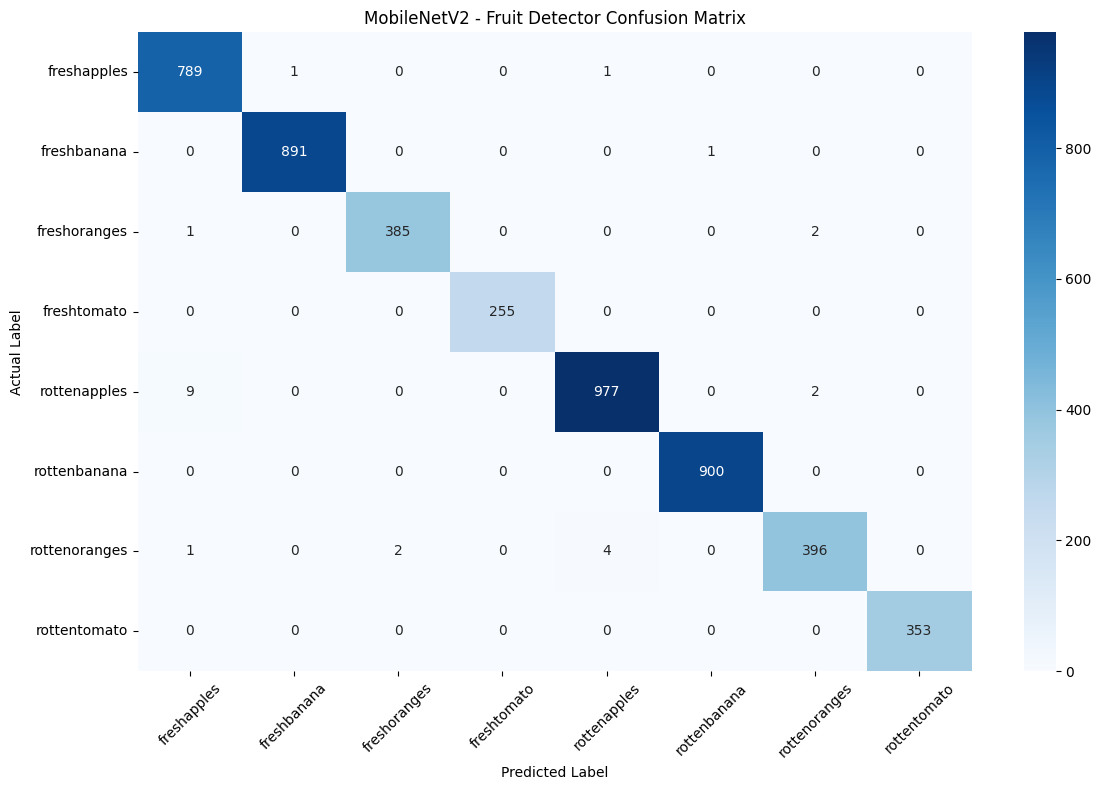

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

# Actual labels
y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

# Predicted labels
y_pred_prob = model.predict(test_ds)
y_pred = np.argmax(y_pred_prob, axis=1)

# Classification report
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(12, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("MobileNetV2 - Fruit Detector Confusion Matrix")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
import os
import json

SAVE_PATH = "/content/drive/MyDrive/Fruit_Detector_Model"

os.makedirs(SAVE_PATH, exist_ok=True)

# Save trained model
model.save(os.path.join(SAVE_PATH, "fruit_detector.keras"))

# Save class names
with open(os.path.join(SAVE_PATH, "class_names.json"), "w") as f:
    json.dump(class_names, f)

print("Model saved successfully!")
print("Class names saved successfully!")

Model saved successfully!
Class names saved successfully!


In [ ]:
import os
import json

SAVE_PATH = "/content/drive/MyDrive/Fruit_Detector_Model"
os.makedirs(SAVE_PATH, exist_ok=True)

# Save model
model.save(f"{SAVE_PATH}/fruit_detector.keras")

# Save class names
with open(f"{SAVE_PATH}/class_names.json", "w") as f:
    json.dump(class_names, f)

print("Model and class names saved!")

Model and class names saved!


In [ ]:
from google.colab import files

files.download(
    "/content/drive/MyDrive/Fruit_Detector_Model/fruit_detector.keras"
)

files.download(
    "/content/drive/MyDrive/Fruit_Detector_Model/class_names.json"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>